<a href="https://colab.research.google.com/github/Digitalbuilder2026/Intro-to-Computer-Vision/blob/main/CV_Plus_Video.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
plt.rcParams['image.cmap'] = 'gray'

In [ ]:
!git clone https://github.com/fenago/cv2

fatal: destination path 'cv2' already exists and is not an empty directory.


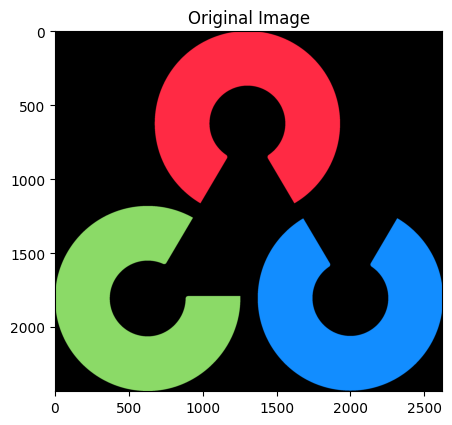

In [ ]:
# Read the image in a 3 channel color format.
img = cv2.imread('/content/cv2/Mod3/opencv_logo.png', cv2.IMREAD_COLOR)

# Display.
plt.figure(figsize = (5, 5))
plt.imshow(img[:, :, ::-1])  # Swap color channels from BGR to RGB
plt.title('Original Image');

In [ ]:
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

In [ ]:
# Four colors written as BGR pixels in a 1 x 4 "image".
colors = np.array([[[0, 0, 255],      # pure red
                    [0, 255, 0],      # pure green
                    [255, 0, 0],      # pure blue
                    [80, 40, 255]]],  # pinkish red
                  dtype = 'uint8')

hsv = cv2.cvtColor(colors, cv2.COLOR_BGR2HSV)
print('Hue values:', hsv[0, :, 0])

Hue values: [  0  60 120 174]


In [ ]:
# Set range for red color.
r_lb = np.array([165, 50, 50], np.uint8)
r_ub = np.array([180, 255, 255], np.uint8)

# Set range for green color.
g_lb = np.array([35, 50, 50], np.uint8)
g_ub = np.array([80, 255, 255], np.uint8)

# Set range for blue color.
b_lb = np.array([95, 50, 50], np.uint8)
b_ub = np.array([125, 255, 255], np.uint8)

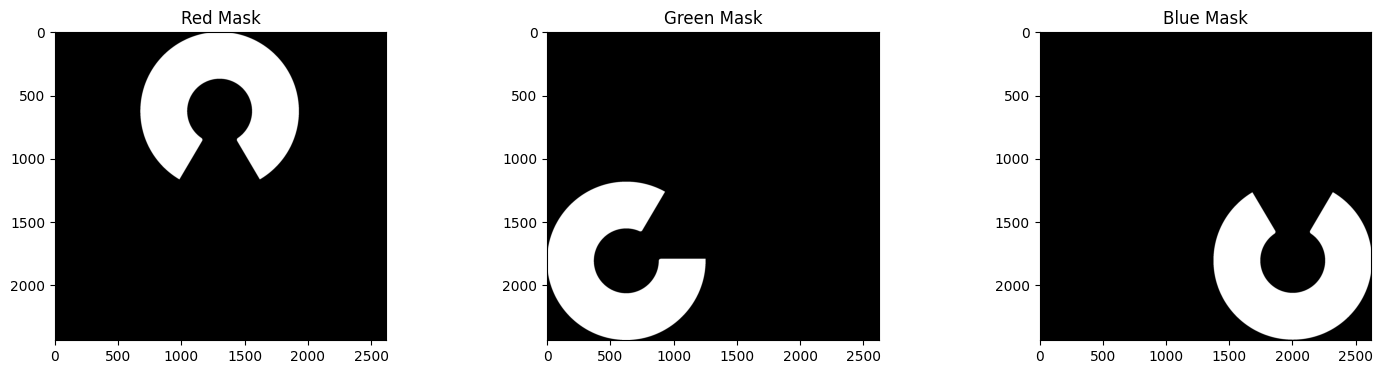

In [ ]:
# Define each color mask.
r_mask = cv2.inRange(img_hsv, r_lb, r_ub)
g_mask = cv2.inRange(img_hsv, g_lb, g_ub)
b_mask = cv2.inRange(img_hsv, b_lb, b_ub)

# Display each color mask.
plt.figure(figsize = (18, 4))
plt.subplot(131); plt.imshow(r_mask); plt.title('Red Mask')
plt.subplot(132); plt.imshow(g_mask); plt.title('Green Mask')
plt.subplot(133); plt.imshow(b_mask); plt.title('Blue Mask');

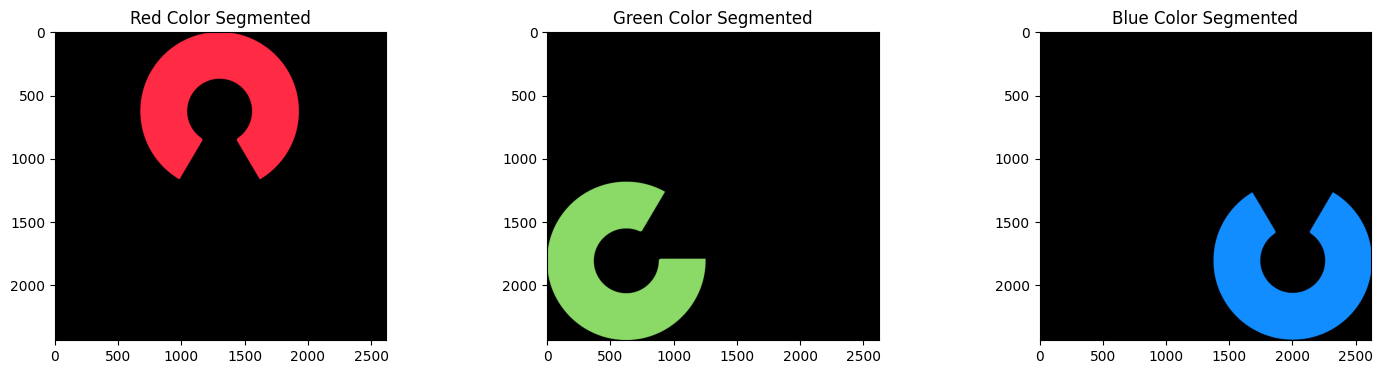

In [ ]:
# Segment the colors.
r_seg = cv2.bitwise_and(img, img, mask = r_mask)
g_seg = cv2.bitwise_and(img, img, mask = g_mask)
b_seg = cv2.bitwise_and(img, img, mask = b_mask)

# Display the segmented colors.
plt.figure(figsize = (18, 4))
plt.subplot(131); plt.imshow(r_seg[:, :, ::-1]); plt.title('Red Color Segmented')
plt.subplot(132); plt.imshow(g_seg[:, :, ::-1]); plt.title('Green Color Segmented')
plt.subplot(133); plt.imshow(b_seg[:, :, ::-1]); plt.title('Blue Color Segmented');

In [ ]:
# Readin the color image: 'Emerald_Lakes_New_Zealand.jpg'
# YOUR CODE HERE

# Convert to HSV (use: cvtColor())
# YOUR CODE HERE

# Specify the lower and upper bound to segment the green lakes in the image.
# YOUR CODE HERE

# Create a green mask (use: inRange())
# YOUR CODE HERE

# Segment the lakes (use bitwise_and())
# YOUR CODE HERE

# Display the original image and the segmented lakes.

# Videos...

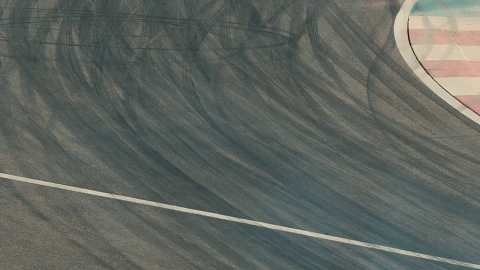

Frame: 540
Total frames read: 560


In [ ]:
import cv2
from google.colab.patches import cv2_imshow
from IPython.display import clear_output

video_cap = cv2.VideoCapture('/content/cv2/Mod3/race_car_slow_motion.mp4')

frame_count = 0
while True:
    has_frame, frame = video_cap.read()
    if not has_frame:
        break
    frame_count += 1

    # Show every 30th frame, at half size, replacing the previous one.
    if frame_count % 30 == 0:
        clear_output(wait = True)
        cv2_imshow(cv2.resize(frame, None, fx = 0.5, fy = 0.5))
        print('Frame:', frame_count)

video_cap.release()
print('Total frames read:', frame_count)

In [ ]:
# # this is the code here to run locally in vs code or similar...
# # Here is the link to get the race car video: https://github.com/fenago/cv2/tree/main/Mod4
# import cv2

# # Use source = 0 to specify the web cam as the video source, OR
# # specify the pathname to a video file to read.
# source = 'race_car_slow_motion.mp4' # if source = 0 then the web cam will be used as the video source

# # Create a video capture object from the VideoCapture Class.
# video_cap = cv2.VideoCapture(source)

# # Create a named window for the video display.
# win_name = 'Video Preview'
# cv2.namedWindow(win_name)

# # Enter a while loop to read and display the video frames one at a time.
# while True:
#     # Read one frame at a time using the video capture object.
#     has_frame, frame = video_cap.read()
#     if not has_frame:
#         break
#     # Display the current frame in the named window.
#     cv2.imshow(win_name, frame)

#     # Use the waitKey() function to monitor the keyboard for user input.
#     # key = cv2.waitKey(0) will display the window indefinitely until any key is pressed.
#     # key = cv2.waitKey(1) # will display the window for 1 ms automatically advancing to the next frame after 1 ms.
#     key = cv2.waitKey(0) # this will advance the movie one frame at a time, and will wait indefinitely for a key press before advancing to the next frame.

#     # The return value of the waitKey() function indicates which key was pressed.
#     # You can use this feature to check if the user selected the `q` key to quit the video stream.
#     if key == ord('Q') or key == ord('q') or key == 27:
#         # Exit the loop.
#         break

#     # Every key on the keyboard has a number. ord() looks it up.
# print("ord('q') =", ord('q'))
# print("ord('Q') =", ord('Q'))
# print("ord('p') =", ord('p'))

# video_cap.release()
# cv2.destroyWindow(win_name)

This lesson's code doesn't include an exercise, so here's a challenge that uses everything you just learned. Run it on your own computer, since it uses desktop windows and the keyboard.

Challenge: Turn the frame stepper into a real player. Make the video play at roughly its true speed, and add a pause feature: pressing p pauses on the current frame, and pressing p again resumes. Keep the three exit keys.

Two hints. First, the true speed needs the video's frame rate, which you can get with video_cap.get(cv2.CAP_PROP_FPS). Second, a pause is just a waitKey(0) that only happens when the user asks for it.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
!pip install moviepy==1.0.3

In [ ]:
# Install moviepy from your terminal or powershell.
# pip install moviepy
from moviepy.editor import VideoFileClip

input_video = '/content/cv2/Mod3/race_car.mp4'

# loading output video
clip = VideoFileClip(input_video)
clip.ipython_display(width = 600)

  from pkg_resources import resource_stream, resource_exists



Moviepy - Building video __temp__.mp4.
MoviePy - Writing audio in __temp__TEMP_MPY_wvf_snd.mp3


MoviePy - Done.
Moviepy - Writing video __temp__.mp4



t:  99%|█████████▊| 233/236 [00:08<00:00, 50.26it/s, now=None]WARNING:py.warnings:/usr/local/lib/python3.13/dist-packages/moviepy/video/io/ffmpeg_reader.py:123: UserWarning: Warning: in file /content/cv2/Mod3/race_car.mp4, 2764800 bytes wanted but 0 bytes read,at frame 235/236, at time 7.83/7.85 sec. Using the last valid frame instead.
  warnings.warn("Warning: in file %s, "%(self.filename)+



Moviepy - Done !
Moviepy - video ready __temp__.mp4


In [ ]:
source = input_video  # source = 0 for webcam

video_cap = cv2.VideoCapture(source)
if (video_cap.isOpened()== False):
  print("Error opening video stream or file")

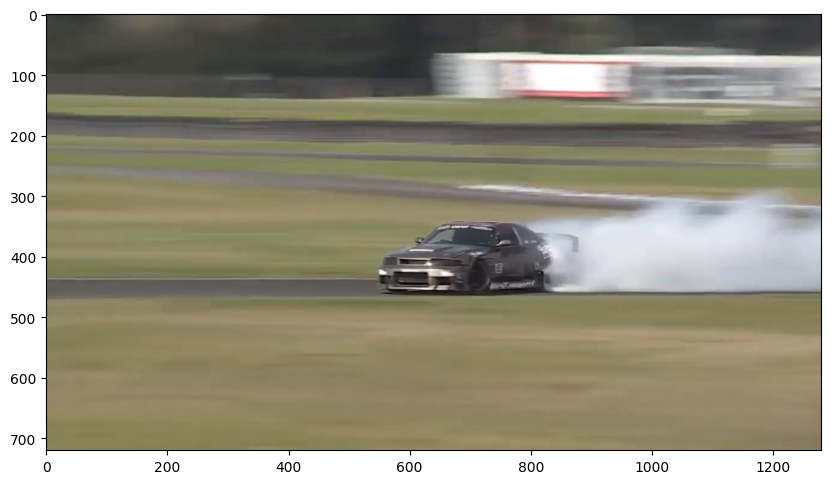

In [ ]:
ret, frame = video_cap.read()
plt.figure(figsize = (10, 8))
plt.imshow(frame[...,::-1])
# plt.imshow(frame[...,::])

In [ ]:
# Retrieve video frame properties.
frame_w   = int(video_cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_h   = int(video_cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
frame_fps = int(video_cap.get(cv2.CAP_PROP_FPS))

In [ ]:
frame_fps

30

In [ ]:
# Specify the value for fourcc
fourcc_avi = cv2.VideoWriter_fourcc('M','J','P','G')
fourcc_mp4 = cv2.VideoWriter_fourcc(*'XVID')

# Specify the video output filenames.
file_out_avi = 'video_out.avi'
file_out_mp4 = 'video_out.mp4'

# Slow down or speed up the speed of the video.
# frame_fps = int(frame_fps*3). speed it up
frame_fps = int(frame_fps/3) # slow it down

# Create the video writer objects.
out_avi = cv2.VideoWriter(file_out_avi, fourcc_avi, frame_fps, (frame_w,frame_h))
out_mp4 = cv2.VideoWriter(file_out_mp4, fourcc_mp4, frame_fps, (frame_w,frame_h))

In [ ]:
def drawBannerText(frame, text, banner_height_percent = 0.05, text_color = (0,255,0)):
    # Draw a black filled banner across the top of the image frame.
    # percent: set the banner height as a percentage of the frame height.
    banner_height = int(banner_height_percent * frame.shape[0])
    cv2.rectangle(frame, (0,0), (frame.shape[1],banner_height), (0,0,0), thickness=-1)

    # Draw text on banner.
    left_offset = 20
    location = (left_offset, int( 5 + (banner_height_percent * frame.shape[0])/2 ))
    fontScale = 1.5
    fontThickness = 2
    cv2.putText(frame, text, location, cv2.FONT_HERSHEY_PLAIN, fontScale, text_color, fontThickness, cv2.LINE_AA)

In [ ]:
# Read all the frames in the video.
frame_count = 0
while True:

    # Read one frame at a time.
    ok, frame = video_cap.read()
    if not ok:
        break

    # Increment the frame count for the annotation.
    frame_count += 1

    # Annotate each video frame.
    drawBannerText(frame, 'Frame: ' + str(int(frame_count)) + ' FPS: ' + str(int(frame_fps)))

    # Write the frame to the output files.
    out_avi.write(frame)
    out_mp4.write(frame)

In [ ]:
# Release the VideoCapture and VideoWriter objects
video_cap.release()
out_avi.release()
out_mp4.release()

In [ ]:
clip = VideoFileClip(file_out_mp4)
clip.ipython_display(width = 600)

Moviepy - Building video __temp__.mp4.
Moviepy - Writing video __temp__.mp4



Moviepy - Done !
Moviepy - video ready __temp__.mp4


Challenge: Create a grayscale version of the race-car video, slowed to half speed, with a banner that reads "Frame:" and the frame number. Save it as race_car_gray.avi, and make sure the first frame is included, labeled "Frame: 1."

Two hints. First, think about Part 6: start with a fresh VideoCapture so no frame has been taken yet. Second, grayscale frames have only one channel, so the writer needs to know: use the optional isColor argument.

Also, please get your own video and put your name or logo or a timestamp on every frame.  Speed it up... slow it down... explore/experiment!